# ML-10 — Content Action Playbook

**Lane:** Refresh / Content Opportunity Scoring. This is a non-production, human-reviewed triage workflow built on the same ML-04/ML-07 warehouse contract and the W06 grouped-validation audit. The model score orders candidates for review; it does not decide that a page should be changed.

## 1. Ranked actions + reason codes

The queue contains only items passing the ML-07 March rule: at least 500 impressions, average position 1–20, and CTR below 0.5%. We rank this same candidate pool with **grouped out-of-fold Logistic Regression scores**: each candidate receives a score from a model trained without that candidate’s client group. The score is a relative ranking signal, **not a calibrated probability or confidence score**. The rule baseline uses the existing `log1p(March impressions)` ranking.

Each item gets one transparent action archetype and reason code. Partial March coverage (20–24 observed days) is routed to a coverage check before any content edit; better-covered page-one candidates go to a snippet/intent review; better-covered positions 11–20 go to a relevance/internal-link review. The first queue position means “review earlier,” not “edit automatically.”

In [1]:
from pathlib import Path
import json
import duckdb
import matplotlib.pyplot as plt
import sklearn
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from IPython.display import display

repo_root = Path.cwd()
while not (repo_root / '.env').is_file() and repo_root != repo_root.parent:
    repo_root = repo_root.parent
if not (repo_root / '.env').is_file():
    raise FileNotFoundError('Repository-root .env with HF_TOKEN is required; the credential is never displayed.')
hf_token = None
for line in (repo_root / '.env').read_text(encoding='utf-8').splitlines():
    if '=' in line and not line.lstrip().startswith('#'):
        key, value = line.split('=', 1)
        if key.strip() == 'HF_TOKEN':
            hf_token = value.strip().strip(chr(34)).strip(chr(39))
            break
if not hf_token or not hf_token.startswith('hf_'):
    raise ValueError('HF_TOKEN is missing or malformed in .env; credential value was not displayed.')
con = duckdb.connect()
con.execute('LOAD httpfs')
con.execute('CREATE OR REPLACE SECRET hf (TYPE huggingface, TOKEN ?)', [hf_token])
del hf_token
warehouse = 'hf://datasets/FlyRank/internship-warehouse/fact_content_daily_performance'
march_source = 'read_parquet(' + repr(warehouse + '/month=2026-03/*.parquet') + ')'
april_source = 'read_parquet(' + repr(warehouse + '/month=2026-04/*.parquet') + ')'
print('Warehouse connection configured from ignored .env; credential was not displayed.')

Warehouse connection configured from ignored .env; credential was not displayed.


In [2]:
feature_sql = f'''
WITH march AS (
    SELECT client_hash_id, content_hash_id,
           COUNT(*) FILTER (WHERE gsc_data_available IS TRUE) AS gsc_days_mar,
           SUM(gsc_impressions) FILTER (WHERE gsc_data_available IS TRUE) AS impressions_mar,
           SUM(gsc_clicks) FILTER (WHERE gsc_data_available IS TRUE) AS clicks_mar,
           SUM(gsc_sum_position) FILTER (WHERE gsc_data_available IS TRUE) AS position_sum_mar
    FROM {march_source}
    GROUP BY client_hash_id, content_hash_id
), april AS (
    SELECT client_hash_id, content_hash_id,
           COUNT(*) FILTER (WHERE gsc_data_available IS TRUE) AS gsc_days_apr,
           SUM(gsc_impressions) FILTER (WHERE gsc_data_available IS TRUE) AS impressions_apr
    FROM {april_source}
    GROUP BY client_hash_id, content_hash_id
)
SELECT march.client_hash_id, march.content_hash_id,
       march.gsc_days_mar, march.impressions_mar, march.clicks_mar,
       march.position_sum_mar / NULLIF(march.impressions_mar, 0) AS avg_position_mar,
       100.0 * march.clicks_mar / NULLIF(march.impressions_mar, 0) AS ctr_mar,
       CAST(april.impressions_apr <= 0.8 * march.impressions_mar AS INTEGER) AS april_decline_label
FROM march INNER JOIN april USING (client_hash_id, content_hash_id)
WHERE march.gsc_days_mar >= 20 AND april.gsc_days_apr >= 20
  AND march.impressions_mar > 0
'''
items = con.execute(feature_sql).df()
con.close()
ID_COLUMNS = ['client_hash_id', 'content_hash_id']
LABEL = 'april_decline_label'
items = items.sort_values(ID_COLUMNS, kind='mergesort').reset_index(drop=True)
assert items[ID_COLUMNS].duplicated().sum() == 0
assert items[LABEL].isin([0, 1]).all()
print(f'Eligible paired client-content items: {len(items):,}; April decline-proxy rate: {items[LABEL].mean():.3f}')
print('March and April each require at least 20 GSC-available days (IS TRUE); target is retrospective, not a causal refresh outcome.')

Eligible paired client-content items: 95,633; April decline-proxy rate: 0.495
March and April each require at least 20 GSC-available days (IS TRUE); target is retrospective, not a causal refresh outcome.


In [3]:
candidate_mask = (
    (items['impressions_mar'] >= 500)
    & (items['avg_position_mar'] > 0)
    & (items['avg_position_mar'] <= 20)
    & (items['ctr_mar'] < 0.5)
)
candidates = items.loc[candidate_mask].copy().reset_index(drop=True)
FEATURES = ['log_impressions_mar', 'log_clicks_mar', 'ctr_mar', 'avg_position_mar', 'gsc_days_mar']
candidates['log_impressions_mar'] = np.log1p(candidates['impressions_mar'])
candidates['log_clicks_mar'] = np.log1p(candidates['clicks_mar'])
candidates['baseline_score'] = candidates['log_impressions_mar']
assert len(candidates) >= 500
assert candidates[LABEL].nunique() == 2

client_groups = candidates['client_hash_id']
n_splits = min(5, client_groups.nunique())
if n_splits < 2:
    raise ValueError('At least two client groups are required for grouped out-of-fold scoring.')
cv = GroupKFold(n_splits=n_splits)
oof_score = np.full(len(candidates), np.nan, dtype=float)
fold_for_row = np.full(len(candidates), -1, dtype=int)
fold_rows = []

def new_model():
    return make_pipeline(
        SimpleImputer(strategy='median'),
        StandardScaler(),
        LogisticRegression(C=1.0, max_iter=2000, random_state=42),
    )

for fold, (train_idx, valid_idx) in enumerate(cv.split(candidates[FEATURES], candidates[LABEL], groups=client_groups), start=1):
    train_frame = candidates.iloc[train_idx]
    valid_frame = candidates.iloc[valid_idx]
    if train_frame[LABEL].nunique() != 2:
        raise ValueError(f'Fold {fold} training data does not contain both target classes.')
    train_clients = set(train_frame['client_hash_id'])
    valid_clients = set(valid_frame['client_hash_id'])
    if not train_clients.isdisjoint(valid_clients):
        raise AssertionError(f'Client overlap found in fold {fold}.')
    fold_model = new_model().fit(train_frame[FEATURES], train_frame[LABEL])
    oof_score[valid_idx] = fold_model.predict_proba(valid_frame[FEATURES])[:, 1]
    fold_for_row[valid_idx] = fold
    fold_rows.append({'fold': fold, 'train_items': len(train_idx), 'heldout_items': len(valid_idx), 'train_clients': len(train_clients), 'heldout_clients': len(valid_clients)})

candidates['model_oof_score'] = oof_score
candidates['oof_fold'] = fold_for_row
assert np.isfinite(candidates['model_oof_score']).all()
assert (candidates['oof_fold'] >= 1).all()
assert candidates.groupby('client_hash_id')['oof_fold'].nunique().max() == 1
print(f'Candidate pool: {len(candidates):,} items across {client_groups.nunique()} client groups; grouped {n_splits}-fold out-of-fold scores assigned to every candidate.')
display(pd.DataFrame(fold_rows))

Candidate pool: 39,545 items across 31 client groups; grouped 5-fold out-of-fold scores assigned to every candidate.


,fold,train_items,heldout_items,train_clients,heldout_clients
0,1,28476,11069,30,1
1,2,30110,9435,30,1
2,3,33161,6384,25,6
3,4,33198,6347,24,7
4,5,33235,6310,15,16


### Archetype → action mapping and decay/refresh insight

Archetypes are simple routing rules from March metrics, not learned clusters or quality labels. The actual warehouse feature set here has no refresh timestamp or content-age attribute, so the queue cannot identify “stale” pages or assert that a specific item needs a refresh. The assigned paper (p. 9) reports that the 31–90-day freshness band had a 7.88:1 growth-to-decline ratio, and that 365+ day content refreshed within 30 days had higher observed health (34.5 vs. 10.7) and impressions (4,039 vs. 71) than the paper's comparison. These are observational group comparisons, not a causal effect estimate; the paper also warns that the 361+ day ratio is unstable (283 growing pages and one declining page). Use the result to motivate checking refresh history and cohort comparability, not as an expected lift or as an input to this queue.

In [4]:
coverage_check = candidates['gsc_days_mar'] < 25
page_one = candidates['avg_position_mar'] <= 10
candidates['archetype'] = np.select(
    [coverage_check, page_one],
    ['Partial-observation candidate', 'Page-one low-CTR candidate'],
    default='Striking-distance low-CTR candidate',
)
candidates['reason_code'] = np.select(
    [coverage_check, page_one],
    ['partial_month_coverage_check', 'page_one_low_ctr'],
    default='positions_11_20_low_ctr',
)
candidates['recommended_action'] = np.select(
    [coverage_check, page_one],
    ['verify_coverage_before_edit', 'review_snippet_and_search_intent'],
    default='review_query_page_fit_and_internal_links',
)

archetype_actions = pd.DataFrame([
    {'Archetype': 'Partial-observation candidate', 'Trigger': '20-24 March GSC-available days', 'Reason code': 'partial_month_coverage_check', 'Action': 'verify_coverage_before_edit', 'Human check': 'Check tracking continuity and compare a complete observation window before changing content.'},
    {'Archetype': 'Page-one low-CTR candidate', 'Trigger': 'At least 25 observed days; position 1-10; CTR <0.5%', 'Reason code': 'page_one_low_ctr', 'Action': 'review_snippet_and_search_intent', 'Human check': 'Review query mix, current SERP features, intent, title/description, and factual accuracy.'},
    {'Archetype': 'Striking-distance low-CTR candidate', 'Trigger': 'At least 25 observed days; position >10 and <=20; CTR <0.5%', 'Reason code': 'positions_11_20_low_ctr', 'Action': 'review_query_page_fit_and_internal_links', 'Human check': 'Check topic fit, missing subtopics, internal links, and whether the page answers the intended question.'},
])
display(archetype_actions)
summary = candidates.groupby(['archetype', 'reason_code', 'recommended_action'], observed=True).agg(
    items=(LABEL, 'size'),
    april_proxy_rate=(LABEL, 'mean'),
    median_model_oof_score=('model_oof_score', 'median'),
).reset_index()
display(summary.round({'april_proxy_rate': 3, 'median_model_oof_score': 3}))

,Archetype,Trigger,Reason code,Action,Human check
0,Partial-observation candidate,20-24 March GSC-available days,partial_month_coverage_check,verify_coverage_before_edit,Check tracking continuity and compare a comple...
1,Page-one low-CTR candidate,At least 25 observed days; position 1-10; CTR ...,page_one_low_ctr,review_snippet_and_search_intent,"Review query mix, current SERP features, inten..."
2,Striking-distance low-CTR candidate,At least 25 observed days; position >10 and <=...,positions_11_20_low_ctr,review_query_page_fit_and_internal_links,"Check topic fit, missing subtopics, internal l..."


,archetype,reason_code,recommended_action,items,april_proxy_rate,median_model_oof_score
0,Page-one low-CTR candidate,page_one_low_ctr,review_snippet_and_search_intent,29932,0.560,0.578
1,Partial-observation candidate,partial_month_coverage_check,verify_coverage_before_edit,1201,0.352,0.245
2,Striking-distance low-CTR candidate,positions_11_20_low_ctr,review_query_page_fit_and_internal_links,8412,0.553,0.534


## 2. Intended use and limits

**Intended use:** a weekly or monthly editorial triage aid. A human editor may review a small, capacity-limited portion of the ranked candidate pool, verify the reason code, inspect the live page and query/SERP context, and decide whether any action is warranted. The score is a relative ranking signal; it is not calibrated, not a forecast of recovery, and not an estimate of the benefit of a refresh.

**Limits:** the target is whether April impressions were at least 20% below March, among items with at least 20 GSC-available days in both months. It is a retrospective association. The workflow is restricted to pages already selected by the ML-07 gate, so it says nothing about excluded pages or whole-inventory ranking. W06 found similar grouped-holdout whole-pool ranking metrics for the model and the rule, despite a difference in top-50 precision on that one split. Grouped out-of-fold scoring below reduces client overlap for the exported queue but does not remove temporal overlap in the outcome definition, selection effects, seasonality, or omitted query/SERP context.

In [5]:
def ranked(frame, score_column):
    if score_column == 'model_oof_score':
        columns = [score_column, 'baseline_score', 'clicks_mar', 'avg_position_mar']
        ascending = [False, False, False, True]
    else:
        columns = [score_column, 'clicks_mar', 'avg_position_mar']
        ascending = [False, False, True]
    return frame.sort_values(columns, ascending=ascending, kind='mergesort').reset_index(drop=True)

def precision_at_k(frame, k):
    return float(frame[LABEL].head(min(k, len(frame))).mean())

model_ranked = ranked(candidates, 'model_oof_score')
baseline_ranked = ranked(candidates, 'baseline_score')
base_rate = float(candidates[LABEL].mean())
metrics = {'candidate_count': int(len(candidates)), 'client_group_count': int(client_groups.nunique()), 'grouped_oof_folds': int(n_splits), 'april_decline_proxy_base_rate': base_rate, 'rankings': {}}
for name, frame, score_col in [
    ('ML-07 rule: log impressions', baseline_ranked, 'baseline_score'),
    ('ML-08 Logistic Regression: grouped OOF', model_ranked, 'model_oof_score'),
]:
    metrics['rankings'][name] = {
        'precision_at_10': precision_at_k(frame, 10),
        'precision_at_20': precision_at_k(frame, 20),
        'precision_at_50': precision_at_k(frame, 50),
        'roc_auc': float(roc_auc_score(candidates[LABEL], candidates[score_col])),
        'average_precision': float(average_precision_score(candidates[LABEL], candidates[score_col])),
    }
comparison = pd.DataFrame([
    {'Ranking': name, 'Candidates': len(candidates), 'Base rate': base_rate, **{
        'Precision@10': vals['precision_at_10'], 'Precision@20': vals['precision_at_20'],
        'Precision@50': vals['precision_at_50'], 'ROC-AUC': vals['roc_auc'],
        'Average precision': vals['average_precision'],
    }}
    for name, vals in metrics['rankings'].items()
]).set_index('Ranking')
print('Grouped out-of-fold comparison on the same ML-07 candidate pool:')
display(comparison.round(3))
print('Treat Precision@K as review-queue performance; base rate is shown for context. Scores and performance are retrospective and directional.')
oof_model_metrics = metrics['rankings']['ML-08 Logistic Regression: grouped OOF']
rule_metrics = metrics['rankings']['ML-07 rule: log impressions']
print(
    f"In these grouped out-of-fold results, model Precision@50 was {oof_model_metrics['precision_at_50']:.3f} "
    f"vs. {rule_metrics['precision_at_50']:.3f} for the rule; ROC-AUC was "
    f"{oof_model_metrics['roc_auc']:.3f} vs. {rule_metrics['roc_auc']:.3f}, and average precision was "
    f"{oof_model_metrics['average_precision']:.3f} vs. {rule_metrics['average_precision']:.3f}. "
    "Interpret this as one retrospective evaluation of this selected pool, not a promise for future pages or months."
)

Grouped out-of-fold comparison on the same ML-07 candidate pool:


,Candidates,Base rate,Precision@10,Precision@20,Precision@50,ROC-AUC,Average precision
Ranking,,,,,,,
ML-07 rule: log impressions,39545,0.552,0.4,0.35,0.40,0.450,0.512
ML-08 Logistic Regression: grouped OOF,39545,0.552,0.8,0.80,0.86,0.595,0.620


Treat Precision@K as review-queue performance; base rate is shown for context. Scores and performance are retrospective and directional.
In these grouped out-of-fold results, model Precision@50 was 0.860 vs. 0.400 for the rule; ROC-AUC was 0.595 vs. 0.450, and average precision was 0.620 vs. 0.512. Interpret this as one retrospective evaluation of this selected pool, not a promise for future pages or months.


## 3. Human review + the no-go list

**Before acting:** verify data coverage and that the page still exists; inspect current search queries and search-result features; confirm search intent and facts; check canonicalization, indexing, migrations, seasonality, and recent site changes; then record the editor’s decision and the reason. If the suggested action does not match the current page context, reject or revise it.

**Do not automate:** writing or publishing content; changing titles, metadata, or structured data; deleting, noindexing, canonicalizing, merging, or redirecting pages; making legal, medical, financial, or other high-impact factual edits; or declaring a page “bad” from a score. These actions require a qualified person and context not present in this dataset.

In [6]:
no_go = pd.DataFrame([
    {'No-go action': 'Auto-generate or publish an update', 'Why': 'The features omit current page content, query intent, SERP context, and fact verification.'},
    {'No-go action': 'Delete, noindex, canonicalize, merge, or redirect from score alone', 'Why': 'No backlink, conversion, business value, or migration context is present.'},
    {'No-go action': 'Treat model score as refresh probability or expected lift', 'Why': 'The score is not calibrated and the observational target does not measure treatment effect.'},
    {'No-go action': 'Use the queue to judge editorial quality or staff performance', 'Why': 'The label captures a noisy impression change, not quality or controllable impact.'},
    {'No-go action': 'Use this rule to rank every site page', 'Why': 'Evaluation and queue are conditional on ML-07 eligibility and adequate monthly GSC coverage.'},
])
display(no_go)

,No-go action,Why
0,Auto-generate or publish an update,"The features omit current page content, query ..."
1,"Delete, noindex, canonicalize, merge, or redir...","No backlink, conversion, business value, or mi..."
2,Treat model score as refresh probability or ex...,The score is not calibrated and the observatio...
3,Use the queue to judge editorial quality or st...,"The label captures a noisy impression change, ..."
4,Use this rule to rank every site page,Evaluation and queue are conditional on ML-07 ...


## 4. Monitoring / retrain triggers

This is a proposed lightweight pilot checklist, **not a production monitoring system**. Review a limited queue (for example, up to 20 candidates per cycle); at an illustrative 15 minutes for initial human triage per item, that is about five editor-hours. This is a capacity-planning example, not a measured cost or a promised return. Track actual review time, accepted/rejected recommendations, completed edits, and subsequent outcomes before making any value claim.

Re-evaluate only after a later, complete outcome window is available. Pause and investigate if data coverage or feature definitions change, if a GSC availability check fails, or if Precision@50 on a comparable future cohort is below both the ML-07 rule and its base rate for two consecutive review cycles. Refit only after checking label timing, client-grouped validation, and feature drift; record a new model version and compare it with the rule. Do not use April outcomes to claim that a refresh caused recovery.

In [7]:
monitoring_plan = pd.DataFrame([
    {'Check': 'Source and coverage', 'Cadence': 'Every run', 'Trigger': 'Availability filter/schema changes or fewer than 20 observed days in either month', 'Response': 'Stop queue generation; verify warehouse contract and coverage before rerunning.'},
    {'Check': 'Human review utility', 'Cadence': 'Each small review cycle', 'Trigger': 'Track review minutes, accept/reject decisions, edits, and reason-code overrides', 'Response': 'Refine workflow only with editor feedback; do not infer causal content lift.'},
    {'Check': 'Prospective ranking performance', 'Cadence': 'After a later complete outcome window', 'Trigger': 'At comparable eligibility, grouped P@50 is below both rule P@50 and candidate base rate for two cycles', 'Response': 'Pause model-led ordering; inspect cohort/label drift and compare again before any refit.'},
    {'Check': 'Model refresh', 'Cadence': 'Only after evidence review', 'Trigger': 'Meaningful schema, population, or feature-definition change', 'Response': 'Version the change and re-run grouped validation against the unchanged simple rule.'},
])
display(monitoring_plan)
print(f'Illustrative review effort: 20 items x 15 minutes = {20 * 15 / 60:.1f} editor-hours; actual effort and value are unmeasured.')

,Check,Cadence,Trigger,Response
0,Source and coverage,Every run,Availability filter/schema changes or fewer th...,Stop queue generation; verify warehouse contra...
1,Human review utility,Each small review cycle,"Track review minutes, accept/reject decisions,...",Refine workflow only with editor feedback; do ...
2,Prospective ranking performance,After a later complete outcome window,"At comparable eligibility, grouped P@50 is bel...",Pause model-led ordering; inspect cohort/label...
3,Model refresh,Only after evidence review,"Meaningful schema, population, or feature-defi...",Version the change and re-run grouped validati...


Illustrative review effort: 20 items x 15 minutes = 5.0 editor-hours; actual effort and value are unmeasured.


## 5. Exports for the paper

Export the complete ranked queue to the ignored `work/outputs/` CSV path, an aggregate-only metrics JSON receipt, and two figures to `work/figures/`. The CSV contains pseudonymous join keys for controlled downstream use; notebook previews and figures omit IDs. The queue intentionally excludes the April outcome and all label-derived fields. The metrics JSON and figures are paper-ready aggregate artifacts and should be committed; the generated queue CSV stays out of Git.

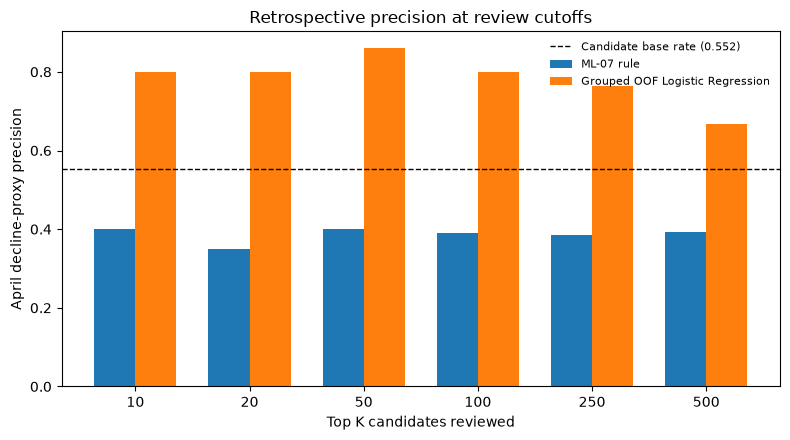

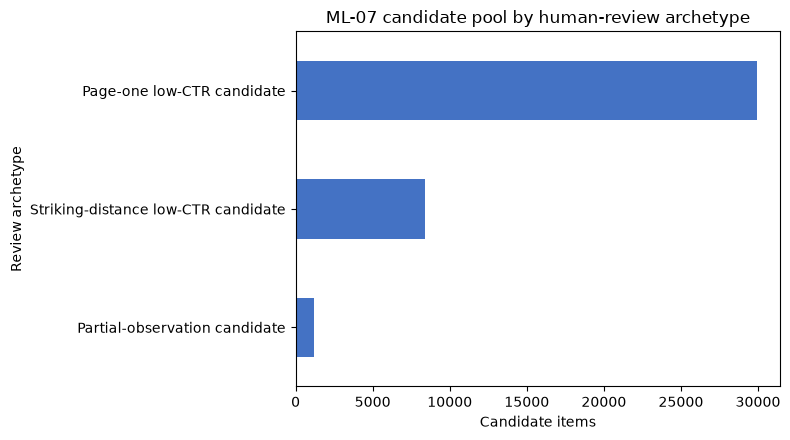

Exported full ranked queue: work\outputs\w07_ranked_action_queue.csv (39,545 rows; ignored by Git).
Exported aggregate metric receipt: work\outputs\w07_action_playbook_metrics.json
Exported figures: work\figures\w07_precision_at_k.png, work\figures\w07_review_archetypes.png
Anonymous top-10 preview:


,rank,priority_score,archetype,reason_code,recommended_action,impressions_mar,avg_position_mar,ctr_mar,gsc_days_mar
0,1,0.831,Page-one low-CTR candidate,page_one_low_ctr,review_snippet_and_search_intent,2975.0,0.200,0.0,31
1,2,0.831,Page-one low-CTR candidate,page_one_low_ctr,review_snippet_and_search_intent,2737.0,0.171,0.0,31
2,3,0.830,Page-one low-CTR candidate,page_one_low_ctr,review_snippet_and_search_intent,3191.0,0.408,0.0,31
3,4,0.829,Page-one low-CTR candidate,page_one_low_ctr,review_snippet_and_search_intent,2934.0,0.426,0.0,31
4,5,0.829,Page-one low-CTR candidate,page_one_low_ctr,review_snippet_and_search_intent,4225.0,0.644,0.0,31
5,6,0.827,Page-one low-CTR candidate,page_one_low_ctr,review_snippet_and_search_intent,937.0,0.115,0.0,31
6,7,0.827,Page-one low-CTR candidate,page_one_low_ctr,review_snippet_and_search_intent,944.0,0.137,0.0,31
7,8,0.826,Page-one low-CTR candidate,page_one_low_ctr,review_snippet_and_search_intent,1652.0,0.577,0.0,31
8,9,0.826,Page-one low-CTR candidate,page_one_low_ctr,review_snippet_and_search_intent,1261.0,0.450,0.0,31
9,10,0.826,Page-one low-CTR candidate,page_one_low_ctr,review_snippet_and_search_intent,1265.0,0.487,0.0,31


In [8]:
outputs_dir = repo_root / 'work' / 'outputs'
figures_dir = repo_root / 'work' / 'figures'
outputs_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

ranked_queue = model_ranked.drop(columns=[LABEL]).copy()
ranked_queue.insert(0, 'rank', np.arange(1, len(ranked_queue) + 1))
ranked_queue['priority_score'] = ranked_queue['model_oof_score']
export_columns = [
    'rank', 'client_hash_id', 'content_hash_id', 'priority_score', 'baseline_score',
    'archetype', 'reason_code', 'recommended_action', 'oof_fold',
    'impressions_mar', 'clicks_mar', 'avg_position_mar', 'ctr_mar', 'gsc_days_mar',
]
forbidden_export_fields = {LABEL, 'impressions_apr', 'trend_pct', 'trend_direction'}
assert not forbidden_export_fields.intersection(ranked_queue.columns)
assert ranked_queue['rank'].is_monotonic_increasing
assert ranked_queue['reason_code'].notna().all() and ranked_queue['recommended_action'].notna().all()
queue_path = outputs_dir / 'w07_ranked_action_queue.csv'
ranked_queue[export_columns].to_csv(queue_path, index=False)

metrics['scope'] = 'ML-07-eligible items only; March 2026 features and April 2026 decline proxy; retrospective association, not causal treatment effect.'
metrics['model'] = {'name': 'L2-regularized Logistic Regression', 'seed': 42, 'validation': '5-fold GroupKFold by client; grouped out-of-fold scores'}
metrics['score_interpretation'] = 'Grouped out-of-fold Logistic Regression ranking score; not calibrated probability or confidence.'
metrics['feature_names'] = FEATURES
metrics['candidate_rule'] = {'march_impressions_min': 500, 'average_position_min_exclusive': 0, 'average_position_max_inclusive': 20, 'ctr_percent_max_exclusive': 0.5}
metrics['minimum_gsc_days_per_month'] = 20
metrics['cv_fold_summaries'] = fold_rows
metrics['action_counts'] = {str(k): int(v) for k, v in candidates['recommended_action'].value_counts().items()}
metrics['library_versions'] = {'numpy': np.__version__, 'pandas': pd.__version__, 'scikit_learn': sklearn.__version__}
metrics['queue_exports_label_or_future_fields'] = False
metrics_path = outputs_dir / 'w07_action_playbook_metrics.json'
metrics_path.write_text(json.dumps(metrics, indent=2, sort_keys=True) + '\n', encoding='utf-8')

ks = [10, 20, 50, 100, 250, 500]
ks = [k for k in ks if k <= len(candidates)]
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(ks))
width = 0.36
rule_values = [precision_at_k(baseline_ranked, k) for k in ks]
model_values = [precision_at_k(model_ranked, k) for k in ks]
ax.bar(x - width / 2, rule_values, width, label='ML-07 rule')
ax.bar(x + width / 2, model_values, width, label='Grouped OOF Logistic Regression')
ax.axhline(base_rate, color='black', linestyle='--', linewidth=1, label=f'Candidate base rate ({base_rate:.3f})')
ax.set_xticks(x, [str(k) for k in ks])
ax.set_xlabel('Top K candidates reviewed')
ax.set_ylabel('April decline-proxy precision')
ax.set_title('Retrospective precision at review cutoffs')
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
precision_figure_path = figures_dir / 'w07_precision_at_k.png'
fig.savefig(precision_figure_path, dpi=160, bbox_inches='tight')
plt.show()
plt.close(fig)

archetype_counts = candidates['archetype'].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
archetype_counts.plot(kind='barh', ax=ax, color='#4472C4')
ax.set_xlabel('Candidate items')
ax.set_ylabel('Review archetype')
ax.set_title('ML-07 candidate pool by human-review archetype')
fig.tight_layout()
archetype_figure_path = figures_dir / 'w07_review_archetypes.png'
fig.savefig(archetype_figure_path, dpi=160, bbox_inches='tight')
plt.show()
plt.close(fig)

print(f'Exported full ranked queue: {queue_path.relative_to(repo_root)} ({len(ranked_queue):,} rows; ignored by Git).')
print(f'Exported aggregate metric receipt: {metrics_path.relative_to(repo_root)}')
print(f'Exported figures: {precision_figure_path.relative_to(repo_root)}, {archetype_figure_path.relative_to(repo_root)}')
print('Anonymous top-10 preview:')
display(ranked_queue[['rank', 'priority_score', 'archetype', 'reason_code', 'recommended_action', 'impressions_mar', 'avg_position_mar', 'ctr_mar', 'gsc_days_mar']].head(10).round(3))

## 6. Self-check

- [x] Ranked queue uses grouped out-of-fold scores and one documented March-only ML-07 candidate gate.
- [x] Every candidate receives a transparent archetype, action, and reason code; action mapping and counts are shown.
- [x] Paper freshness/decay evidence is described as observational and its tiny 361+ declining bucket is disclosed; the current queue lacks refresh-age features.
- [x] Intended use, limitations, human verification, no-go automation, monitoring, and illustrative review effort are explicit.
- [x] The score is not called calibrated confidence; no refresh benefit is claimed.
- [x] Queue CSV omits outcome/label-derived columns and is ignored by Git; metrics JSON and figures are aggregate-only exports for the paper.
- [x] Notebook executed top to bottom under Python 3.11; credentials and pseudonymous IDs are not printed.